# 05. Покрытие и декодирование METAR расширенного пилота

## 1. Дизайн и происхождение данных

EDDF/EHAM/LEMD, полные январь и июль 2019 года по C40 UTC.
Выбор станций и месяцев зафиксирован до загрузки в [протоколе](04_expansion_protocol.ipynb).
Сохраняются обе метки и все исходные строки. Число пригодных сообщений
характеризует техническое качество сопоставления, а не точность модели.
[Архив IEM](https://mesonet.agron.iastate.edu/info/datasets/metar.html).


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
expanded=json.loads((R/'08_pilot_manifest.json').read_text(encoding='utf8'))
journal=json.loads((R/'09_decode_manifest.json').read_text(encoding='utf8'))
features=pd.read_parquet(DATA/'09_pilot_features.parquet')
reports=pd.read_parquet(DATA/'09_decoded_reports.parquet')
assert len(features)==expanded['rows'] and features.source_row.is_unique
assert int(features.GoA.sum())==expanded['go_arounds']
for source in expanded['downloads']:
    assert sha(DATA/'raw'/f"{source['airport']}_{source['month']}.csv")==source['sha256']
display(pd.DataFrame(expanded['downloads'])[['airport','month','raw_reports','identical_duplicates','ambiguous_times','correction_reports']])
display(pd.DataFrame([journal]).T.rename(columns={0:'Значение'}))


,airport,month,raw_reports,identical_duplicates,ambiguous_times,correction_reports
0,EDDF,2019-01,1535,0,0,0
1,EDDF,2019-07,1536,0,0,0
2,EHAM,2019-01,1534,0,0,0
3,EHAM,2019-07,1535,0,0,0
4,LEMD,2019-01,1536,0,0,0
5,LEMD,2019-07,1540,0,0,0


,Значение
rows,94384
go_arounds,201
raw_reports,9216
unique_reports,9216
reports_with_issues,2
matched_residual_rows,22
matched_residual_go_arounds,0
candidates,94348
candidate_go_arounds,201
candidates_without_cor,94348


## 2. Верификация сопоставления на момент C40

Повторно выполняется выбор последнего наблюдения строго до C40.
Разные тексты на одной отметке не заменяются более старым сообщением.
Основной предел давности — 60 минут, дополнительные — 30 и 90 минут.
Время наблюдения не является подтвержденным временем доступности METAR.


,airport,month,GoA,max_age_minutes,rows,covered,coverage_percent,ambiguous,correction_matches
1,EDDF,2019-01,False,60,15262,15262,100.000000,0,0
4,EDDF,2019-01,True,60,35,35,100.000000,0,0
7,EDDF,2019-07,False,60,20045,20045,100.000000,0,0
10,EDDF,2019-07,True,60,81,81,100.000000,0,0
13,EHAM,2019-01,False,60,12537,12537,100.000000,0,0
16,EHAM,2019-01,True,60,24,24,100.000000,0,0
19,EHAM,2019-07,False,60,16731,16731,100.000000,0,0
22,EHAM,2019-07,True,60,21,21,100.000000,0,0
25,LEMD,2019-01,False,60,13621,13607,99.897218,0,0
28,LEMD,2019-01,True,60,12,12,100.000000,0,0


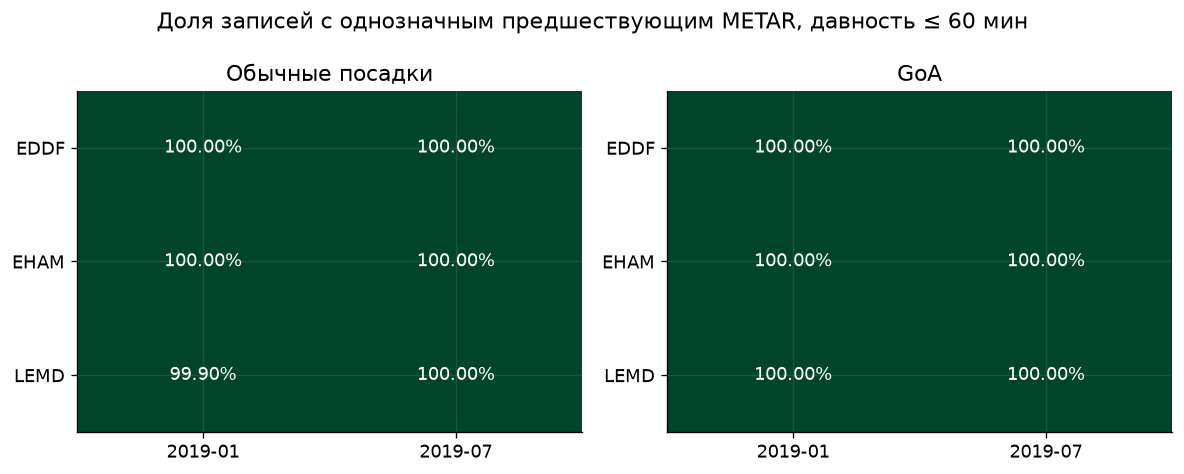

In [3]:
matches=pd.read_parquet(DATA/'08_pilot_matches.parquet')
for source in expanded['downloads']:
    airport,month=source['airport'],source['month']
    raw=pd.read_csv(DATA/'raw'/f'{airport}_{month}.csv',dtype=str,keep_default_na=False)
    assert raw.station.eq(airport).all()
    raw['metar_utc']=pd.to_datetime(raw.valid,utc=True).astype('datetime64[ns, UTC]')
    raw=raw.drop_duplicates(['metar_utc','metar'])
    raw['ambiguous']=raw.duplicated('metar_utc',keep=False)
    right=raw.drop_duplicates('metar_utc').sort_values('metar_utc')
    part=matches.loc[matches.airport.eq(airport)&matches.month.eq(month)].sort_values('C40_CROSS_TIME')
    repeated=pd.merge_asof(part[['source_row','C40_CROSS_TIME']],right[['metar_utc','metar','ambiguous']],
        left_on='C40_CROSS_TIME',right_on='metar_utc',direction='backward',allow_exact_matches=False,tolerance=pd.Timedelta(minutes=90))
    repeated.loc[repeated.ambiguous.eq(True),'metar']=None
    pd.testing.assert_frame_equal(repeated[['source_row','metar_utc','metar']].reset_index(drop=True),
        part[['source_row','metar_utc','metar']].reset_index(drop=True))
coverage=pd.read_csv(R/'08_coverage.csv')
display(coverage.loc[coverage.max_age_minutes.eq(60)])
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,label in zip(axes,[False,True]):
    table=coverage.loc[coverage.GoA.eq(label)&coverage.max_age_minutes.eq(60)].pivot(index='airport',columns='month',values='coverage_percent')
    im=ax.imshow(table.values,vmin=0,vmax=100,cmap='YlGn',aspect='auto')
    for i in range(len(table)):
        for j in range(len(table.columns)):
            ax.text(j,i,f'{table.iloc[i,j]:.2f}%',ha='center',va='center',color='white' if table.iloc[i,j]>70 else 'black')
    ax.set(xticks=range(len(table.columns)),xticklabels=table.columns,yticks=range(len(table)),yticklabels=table.index,title='GoA' if label else 'Обычные посадки')
fig.suptitle('Доля записей с однозначным предшествующим METAR, давность ≤ 60 мин')
save('14_expansion_coverage')


## 3. Верификация декодирования и форматов сообщения

Каждый сырой текст повторно декодируется, а результат сравнивается с сохраненной
таблицей по всем полям. Прогнозные группы отделяются от наблюдения; единицы и
коды пропусков сохраняются. Неизвестные токены и расхождения дают замечание,
а не автоматическое исправление. Применяется тот же декодер, что в первом пилоте.


In [4]:
from decode_metar import decode
display(pd.DataFrame([{'Сохраненный SHA256 декодера':journal['decoder_sha256'],
    'Текущий SHA256 декодера':sha(BASE/'scripts/decode_metar.py')}]))
decoded=[]
for source in expanded['downloads']:
    raw=pd.read_csv(DATA/'raw'/f"{source['airport']}_{source['month']}.csv",dtype=str,keep_default_na=False)
    for row in raw.itertuples(index=False):
        value=decode(row.metar,row.station,pd.Timestamp(row.valid,tz='UTC').to_pydatetime())
        value['archive_month']=source['month']
        decoded.append(value)
repeated=pd.DataFrame(decoded)
repeated['metar_utc']=pd.to_datetime(repeated.metar_utc,utc=True).astype('datetime64[ns, UTC]')
pd.testing.assert_frame_equal(repeated,reports,check_dtype=False)
formats=reports.groupby('station').agg(reports=('metar_id','size'),valid_full_text=('decoded_candidate','sum'),
    trend=('has_trend','sum'),cor=('correction_reported','sum'),cavok=('cavok','sum'))
display(formats)
display(reports.groupby(['station','wind_unit','qnh_unit'],dropna=False).size().rename('reports').reset_index())
residual=pd.read_csv(R/'09_decode_residuals.csv',keep_default_na=False)
display(residual.groupby(['station','decode_issues']).agg(reports=('metar_id','size'),
    matched_rows=('matched_rows','sum'),GoA=('matched_go_arounds','sum')).reset_index())


,Сохраненный SHA256 декодера,Текущий SHA256 декодера
0,fd0924408aba7db677231ec88dc485324777154bbcf008a32aad75cf92aa8c2d,6c1fc46f433a30a870d48d20c0c0e9c7d342e40a8612194a412ba1b618faf9bb


,reports,valid_full_text,trend,cor,cavok
station,,,,,
EDDF,3071,3071,3071,0,1133
EHAM,3069,3068,3069,0,748
LEMD,3076,3075,3075,0,2236


,station,wind_unit,qnh_unit,reports
0,EDDF,KT,hPa,3071
1,EHAM,KT,hPa,3069
2,LEMD,KT,hPa,3076


,station,decode_issues,reports,matched_rows,GoA
0,EHAM,parser_error,1,5,0
1,LEMD,parser_error,1,17,0


## 4. Сообщения с замечаниями и заполненность основных полей

Ниже приводятся все сообщения с замечаниями, их исходные тексты и число
связанных записей. Это диагностический реестр; наличие замечания не доказывает
ошибку источника. Пропуск порыва или потолка облачности не интерпретируется как ноль.


station,metar_utc,metar,decode_issues,matched_rows,matched_go_arounds
EHAM,2019-01-18 04:55:00+00:00,EHAM 180455Z 17003KT CAVOK M02/M02 Q1017 06/1///95 NOSIG,parser_error,5,0
LEMD,2019-01-23 20:30:00+00:00,LEMD 232030Z 28013KT 9999 SCT050 SCT070 13/04 Q1007 WS R36L WS 36R NOSIG,parser_error,17,0


,wind_speed_kt,wind_gust_kt,visibility_m,cloud_ceiling_ft,temperature_c,dewpoint_c,qnh_hpa
airport,,,,,,,
EDDF,100.0,3.70,100.0,32.84,100.0,100.0,100.0
EHAM,100.0,1.92,100.0,36.17,100.0,100.0,100.0
LEMD,100.0,6.38,100.0,4.58,100.0,100.0,100.0


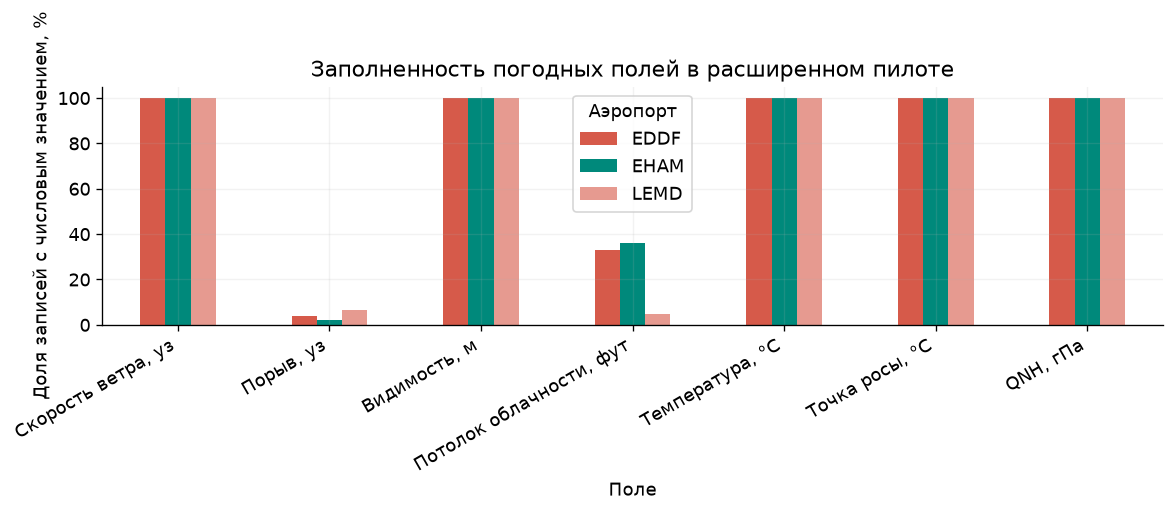

In [5]:
readable_table(residual[['station','metar_utc','metar','decode_issues','matched_rows','matched_go_arounds']])
fields=['wind_speed_kt','wind_gust_kt','visibility_m','cloud_ceiling_ft','temperature_c','dewpoint_c','qnh_hpa']
present=features.groupby('airport')[fields].agg(lambda s:100*s.notna().mean())
display(present.round(2))
fig,ax=plt.subplots(figsize=(10,4))
present.T.plot.bar(ax=ax)
ax.set(ylabel='Доля записей с числовым значением, %',xlabel='Поле',ylim=(0,105),title='Заполненность погодных полей в расширенном пилоте')
ax.legend(title='Аэропорт')
ax.tick_params(axis='x',rotation=30)
ax.set_xticklabels(['Скорость ветра, уз','Порыв, уз','Видимость, м',
    'Потолок облачности, фут','Температура, °C','Точка росы, °C','QNH, гПа'],rotation=30,ha='right')
save('15_expansion_field_presence')


## 5. Диагностические сценарии качества

Кандидат требует однозначного предшествующего METAR в пределах 60 минут
и полного декодирования без замечаний. Дополнительно рассматривается отсутствие
COR в выбранном сообщении. Эти флаги не являются принятым правилом исключения.
Сравнение долей между этапами описательное: состав станций и движения различается.


,airport,month,GoA,rows,candidates,candidates_without_cor
0,EDDF,2019-01,False,15262,15262,15262
1,EDDF,2019-01,True,35,35,35
2,EDDF,2019-07,False,20045,20045,20045
3,EDDF,2019-07,True,81,81,81
4,EHAM,2019-01,False,12537,12532,12532
5,EHAM,2019-01,True,24,24,24
6,EHAM,2019-07,False,16731,16731,16731
7,EHAM,2019-07,True,21,21,21
8,LEMD,2019-01,False,13621,13590,13590
9,LEMD,2019-01,True,12,12,12


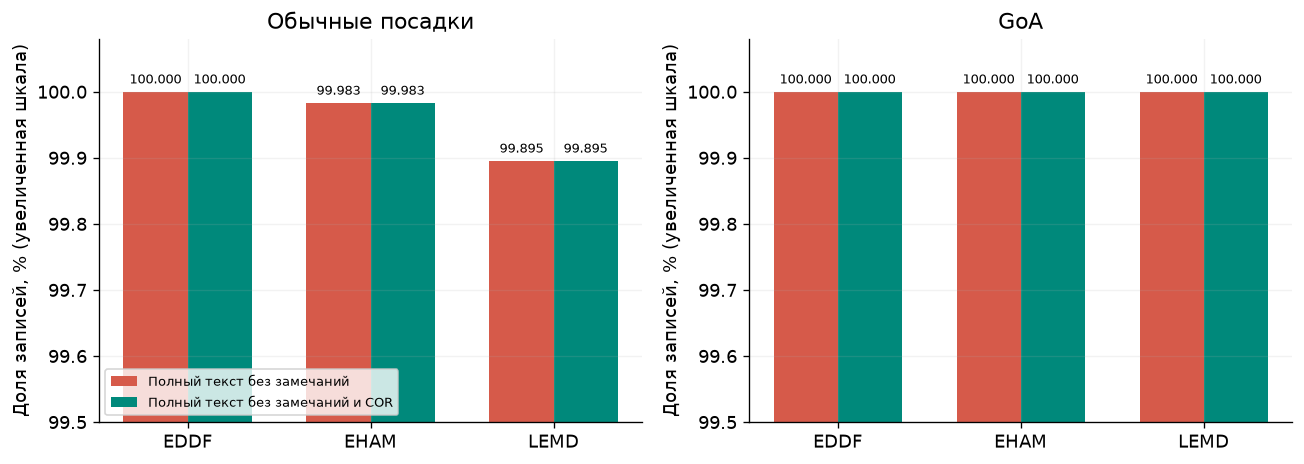

In [6]:
summary=pd.read_csv(R/'09_quality_summary.csv')
display(summary)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,label in zip(axes,[False,True]):
    grouped=summary.loc[summary.GoA.eq(label)].groupby('airport')[['rows','candidates','candidates_without_cor']].sum()
    for i,field in enumerate(['candidates','candidates_without_cor']):
        bars=ax.bar(np.arange(len(grouped))+(i-.5)*.35,100*grouped[field]/grouped.rows,width=.35,
            color=[CORAL,GREEN][i],label=['Полный текст без замечаний','Полный текст без замечаний и COR'][i])
        ax.bar_label(bars,fmt='%.3f',fontsize=8,padding=3)
    ax.set(xticks=np.arange(len(grouped)),xticklabels=grouped.index,ylim=(99.5,100.08),ylabel='Доля записей, % (увеличенная шкала)',title='GoA' if label else 'Обычные посадки')
axes[0].legend(fontsize=8,loc='lower left')
save('16_expansion_quality_scenarios')


## 6. Ограничения и дальнейшая проверка

Историческая доступность сообщения и целевого аэропорта к C40 не подтверждена.
Три новые станции и два месяца не обеспечивают репрезентативность всей базы.
Следующие проверки: классификация остаточных случаев, отдельная верификация
основных полей и чувствительность к задержке публикации по методу ноутбука 03.
Обучение модели и загрузка для всех аэропортов пока не выполнялись.


In [7]:
import unittest, test_decode_metar
outcome=unittest.TextTestRunner(verbosity=1,stream=sys.stdout).run(unittest.defaultTestLoader.loadTestsFromModule(test_decode_metar))
assert outcome.wasSuccessful()
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==expanded['input_sha256']
assert len(features)==94384 and int(features.GoA.sum())==201


.

.

.

.

.

...

.

.

.

.

----------------------------------------------------------------------
Ran 14 tests in 0.013s

OK
